In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

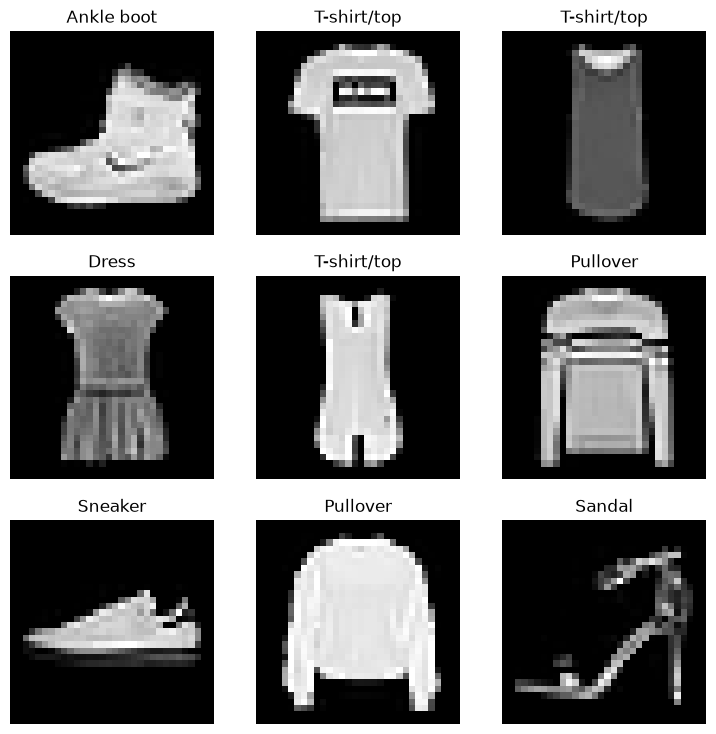

In [2]:
from torch.utils.data import ConcatDataset, DataLoader, RandomSampler, random_split

transforms = v2.Compose([
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True),
    v2.Pad(2) # In the original paper, the backgrounds of images were extended to 32x32
])

_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transforms,
)

_test = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transforms
)

labels_map = {i:c for c, i in _train.class_to_idx.items()}

classes = len(labels_map)

figure = plt.figure(figsize=(9, 9))

cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = i - 1
    img, label = _train[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [3]:
print(classes)

10


In [4]:
dataset = ConcatDataset([_train, _test])

train_data, valid_data, test_data = random_split(
    dataset,
    [0.6, 0.2, 0.2],
    generator=torch.Generator().manual_seed(42),
)

batch_size = 64

train_sampler = RandomSampler(
    train_data,
    replacement=True,
    num_samples=len(train_data),
)

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    sampler=train_sampler,
)

valid_loader = DataLoader(valid_data, batch_size=batch_size)
test_loader = DataLoader(test_data, batch_size=batch_size)

In [5]:
class Subsample2d(nn.Module):
    def __init__(self, in_channels, *args, **kwargs):
        super().__init__()
        
        # Forward the arguments to AvgPool2d
        # Following to the paper, the divisor override of the avg pool should be 1
        # This won't affect training because the weight will be learned anyway
        self.avg_pool = nn.AvgPool2d(*args, **{**kwargs, "divisor_override": 1}) 

        # Separate weight/bias for each channel
        self.weight = nn.Parameter(torch.randn(in_channels))
        self.bias = nn.Parameter(torch.randn(in_channels))

    def forward(self, x):
        # σ(weight * avg_pool(x) + bias)

        pre = self.avg_pool(x)
        w = self.weight[None, :, None, None]
        b = self.bias[None, :, None, None]
        return torch.sigmoid(w * pre + b)

# I got this from ChatGPT. Don't worry, I CAN explain the code.
class C3(nn.Module):
    def __init__(self):
        super().__init__()

        # Sparse connections as seen in the paper. 
        # This is done to introduce asymmetry in the hopes that the parameters learn different features
        # Sparse connections also reduce the memory footprint
        self.connections = [
            # Contiguous subsets of 3 
            [0, 1, 2],
            [1, 2, 3],
            [2, 3, 4],
            [3, 4, 5],
            [0, 4, 5],
            [0, 1, 5],
            
            # Contiguous subsets of 4
            [0, 1, 2, 3],
            [1, 2, 3, 4],
            [2, 3, 4, 5],
            [0, 3, 4, 5],
            [0, 1, 4, 5],
            [0, 1, 2, 5],

            # Disctoninuous subsets of 4
            [0, 1, 3, 4],
            [1, 2, 4, 5],
            [0, 2, 3, 5],

            # All channels
            [0, 1, 2, 3, 4, 5]
        ]

        assert len(self.connections) == 16

        self.convs = nn.ModuleList([
            nn.Conv2d(len(channels), 1, kernel_size=5) # yields oH=10, oW=10 feature maps
                                                       # Note iH=16, iW=16
            for channels in self.connections
        ])

    def forward(self, x):
        outputs = [
            conv(x[:, channels])
            for channels, conv in zip(self.connections, self.convs)
        ]
        return torch.cat(outputs, dim=1)
        


class LeNet5(nn.Module):
    def __init__(self, use_C3=False):
        super().__init__()

        self.conv_subsample_stack = nn.Sequential(
            nn.Conv2d(1, 6, 5),           # in_channels, out_channels, kernel_size
            Subsample2d(6, 2, stride=2),  # in_channels, kernel_size, then kwargs
            C3() if use_C3 else nn.Conv2d(6, 16, 5),
            Subsample2d(16, 2, stride=2),
            # At this point, the output takes on shape (batches, 16, 5, 5)
            nn.Conv2d(16, 120, 5)
        )

        self.linear = nn.Linear(120, classes)
        # shape of output: (batches, 120, 1, 1)
    def forward(self, x):
        prelin = self.conv_subsample_stack(x)
        return self.linear(prelin.squeeze())

In [6]:
# Slight deviation from the original paper; will use cross entropy loss instead

# Note to self: use named_modules to iterate over each layer
# https://www.geeksforgeeks.org/deep-learning/how-to-iterate-over-layers-in-pytorch/

In [7]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [8]:
criterion = nn.CrossEntropyLoss()
model = LeNet5().to(device)
optimizer = optim.SGD([p for p in model.parameters()])

num_epochs = 10

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    # Loss for this epoch
    train_loss /= len(train_data)

    # Validation
    model.eval()
    valid_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            valid_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    valid_loss /= total
    accuracy = correct / total

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Valid Loss: {valid_loss:.4f} | "
        f"Valid Accuracy: {accuracy:.2%}"
    )

Epoch 1/10 | Train Loss: 2.3066 | Valid Loss: 2.3028 | Valid Accuracy: 11.84%
Epoch 2/10 | Train Loss: 2.3009 | Valid Loss: 2.2986 | Valid Accuracy: 13.18%
Epoch 3/10 | Train Loss: 2.2950 | Valid Loss: 2.2913 | Valid Accuracy: 16.29%
Epoch 4/10 | Train Loss: 2.2824 | Valid Loss: 2.2716 | Valid Accuracy: 17.36%
Epoch 5/10 | Train Loss: 2.2483 | Valid Loss: 2.2174 | Valid Accuracy: 42.37%
Epoch 6/10 | Train Loss: 2.1647 | Valid Loss: 2.1034 | Valid Accuracy: 43.86%
Epoch 7/10 | Train Loss: 2.0155 | Valid Loss: 1.9259 | Valid Accuracy: 51.29%
Epoch 8/10 | Train Loss: 1.8174 | Valid Loss: 1.7158 | Valid Accuracy: 54.44%
Epoch 9/10 | Train Loss: 1.6105 | Valid Loss: 1.5243 | Valid Accuracy: 56.60%
Epoch 10/10 | Train Loss: 1.4387 | Valid Loss: 1.3806 | Valid Accuracy: 57.61%
